In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/content/fN1gZQiWAKCzARne.csv")
print(df.head())
print(df.columns.tolist())

   customer_id  annual_spend_k  purchase_frequency_per_month  \
0         9015            56.8                           2.7   
1         9011            10.1                          11.4   
2         9007            17.2                          11.5   
3         9028            28.5                           5.8   
4         9016            42.3                           1.5   

   avg_basket_value  loyalty_years  
0              3028            4.3  
1               623            0.9  
2               613            2.4  
3              1082            3.5  
4              3966            4.3  
['customer_id', 'annual_spend_k', 'purchase_frequency_per_month', 'avg_basket_value', 'loyalty_years']


In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
X= df[['annual_spend_k','purchase_frequency_per_month','avg_basket_value','loyalty_years']]

In [34]:
scaler = StandardScaler()
X_scaler = scaler.fit_transform(X)
X_scaler

array([[ 1.83164871, -0.80318439,  0.78658205,  0.58994749],
       [-1.34263003,  1.67277379, -0.84480552, -1.30035547],
       [-0.86003091,  1.70123308, -0.85158883, -0.46639828],
       [-0.09195062,  0.07905358, -0.5334513 ,  0.14517033],
       [ 0.84605895, -1.14469586,  1.42285712,  0.58994749],
       [-0.69689881,  1.81507024, -0.88550541, -1.02236974],
       [-0.99597432,  0.73361724, -1.05576665, -1.46714691],
       [-0.22109686, -0.14862073, -0.58907449,  0.75673893],
       [-0.01718174, -0.5185915 , -0.20446046, -0.18841255],
       [ 1.70929963, -1.20161444,  1.2315676 ,  1.86868186],
       [-0.37063462, -0.31937647, -0.20988711,  0.36755891],
       [-0.58134691,  1.35972161, -1.01778008, -1.35595262],
       [ 1.13154012, -0.94548084,  1.96213076,  1.03472466],
       [-0.26187988, -0.03478358, -0.23091539, -0.68878687],
       [-0.41141764,  0.13597216, -0.26144032, -0.63318972],
       [ 1.28107788, -1.20161444,  0.45284289,  2.59144475],
       [ 0.38385134, -1.

In [35]:
kmeans = KMeans(n_clusters = 3, random_state= 42, n_init=10)

In [36]:
df['cluster']= kmeans.fit_predict(X_scaler)

In [37]:
df.head()

,customer_id,annual_spend_k,purchase_frequency_per_month,avg_basket_value,loyalty_years,cluster
0,9015,56.8,2.7,3028,4.3,1
1,9011,10.1,11.4,623,0.9,2
2,9007,17.2,11.5,613,2.4,2
3,9028,28.5,5.8,1082,3.5,0
4,9016,42.3,1.5,3966,4.3,1


In [38]:
df['cluster'].value_counts()

,count
cluster,
0,13
2,12
1,11


In [39]:
import seaborn as sns

<Axes: xlabel='annual_spend_k', ylabel='avg_basket_value'>

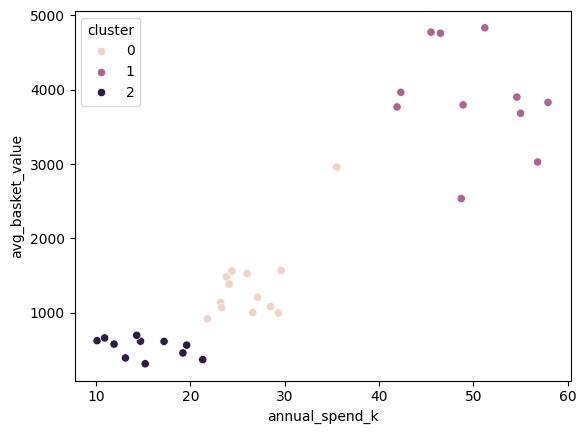

In [40]:
sns.scatterplot(df,x= 'annual_spend_k', y = 'avg_basket_value',hue = 'cluster')

In [44]:
inertias = []
for k in range(2,8):
  km = KMeans(n_clusters=k, random_state=42, n_init =10)
  km.fit(X_scaler)
  inertias.append(km.inertia_)
  print(k, round(km.inertia_,2))

2 40.94
3 20.81
4 17.49
5 14.96
6 12.89
7 11.11


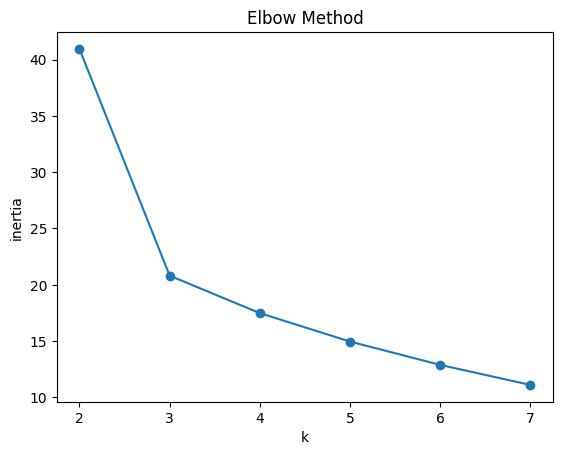

In [45]:
plt.plot(range(2,8),inertias, marker ='o')
plt.xlabel("k")
plt.ylabel("inertia")
plt.title("Elbow Method")
plt.show()

In [46]:
from sklearn.metrics import silhouette_score
sil_scores =[]
for k in range(2,8):
  km = KMeans(n_clusters=k, random_state=42, n_init =10)
  labels = km.fit_predict(X_scaler)
  sil = silhouette_score(X_scaler, labels)
  sil_scores.append(sil)
  print(k, round(sil,3))


2 0.608
3 0.539
4 0.456
5 0.352
6 0.287
7 0.317


In [49]:
#cluster profiling
cluster_profile = df.groupby("cluster")[["annual_spend_k", "purchase_frequency_per_month","avg_basket_value", "loyalty_years"]].mean().round(2)
print(cluster_profile)

         annual_spend_k  purchase_frequency_per_month  avg_basket_value  \
cluster                                                                   
0                 26.40                          4.68           1375.92   
1                 49.94                          1.80           3898.18   
2                 15.18                          9.85            541.33   

         loyalty_years  
cluster                 
0                 2.92  
1                 5.42  
2                 1.58  


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



In [ ]:
X_churn = churn_df[["age", "monthly_spend", "tenure_months", "support_tickets",
                     "contract_type", "used_mobile_app"]]
y_churn = churn_df["churned"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.25, random_state=42, stratify=y_churn
)

In [ ]:
cat_cols = ["contract_type", "used_mobile_app"]
num_cols = ["age", "monthly_spend", "tenure_months", "support_tickets"]

pre_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(drop="if_binary"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
pre_plain = ColumnTransformer([("cat", OneHotEncoder(drop="if_binary"), cat_cols)], remainder="passthrough")


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

churn_df = pd.read_csv("customer_churn.csv")
X_churn = churn_df[["age", "monthly_spend", "tenure_months", "support_tickets",
                     "contract_type", "used_mobile_app"]]
y_churn = churn_df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X_churn, y_churn, test_size=0.25, random_state=42, stratify=y_churn
)

cat_cols = ["contract_type", "used_mobile_app"]
num_cols = ["age", "monthly_spend", "tenure_months", "support_tickets"]

pre_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(drop="if_binary"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
pre_plain = ColumnTransformer([("cat", OneHotEncoder(drop="if_binary"), cat_cols)], remainder="passthrough")

models = {
    "Logistic Regression": Pipeline([("pre", pre_scaled), ("model", LogisticRegression(max_iter=1000))]),
    "Decision Tree": Pipeline([("pre", pre_plain), ("model", DecisionTreeClassifier(max_depth=3, random_state=42))]),
    "Random Forest": Pipeline([("pre", pre_plain), ("model", RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42))]),
}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 3),
        "Precision": round(precision_score(y_test, preds), 3),
        "Recall": round(recall_score(y_test, preds), 3),
        "F1": round(f1_score(y_test, preds), 3),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

In [ ]:
rf_model = models["Random Forest"]
feature_names = rf_model.named_steps["pre"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_

ranked = sorted(zip(feature_names, importances), key=lambda t: -t[1])
for name, score in ranked:
    print(f"{name}: {score:.4f}")

top_feature, top_score = ranked[0]
print(f"\nTop driver: {top_feature} ({top_score:.1%} of splitting usefulness)")